# Data mentioned in the text of the Dates section
Every number cited in the Dates section of the paper, recomputed from the database and the enriched parquets, or read from the method notebook that computes it (model scores, cleaning steps). Each cell names the table, figure or paragraph it supports.

In [1]:
import json
import sys
import tempfile
from pathlib import Path

import duckdb
import polars as pl
from IPython.display import Image, display

sys.path.insert(0, '../notebooks_analysis')
from style import show_table

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only
PARQUETS = Path('../../data/enriched_parquets')
AGE_AT_DEATH = PARQUETS / 'individual_dates_from_age_at_death.parquet'  # 01_age_at_death
ACTIVE_LIFE = PARQUETS / 'individual_active_life.parquet'  # 03_b_active_life
COARSE = PARQUETS / 'individual_coarse_dates.parquet'  # 05_coarse_dates
CUTOFF = 1500
WAR_YEARS = [(1914, 1918), (1939, 1945)]
MILITARY = ['Q47064', 'Q189290', 'Q4991371']  # military personnel, military officer, soldier
ROYAL_OCCUPATIONS = ['Q2478141', 'Q116', 'Q12097']  # aristocrat, monarch, king
ROYAL_WORDS = r'\b(prince|princess|emperor|empress|king|queen|royal|heir|duke|duchess|dauphin|infante|infanta|tsarevich|archduke|archduchess)\b'
CHILD_AGE = 15
TABLE_6 = ['Q798589', 'Q648938', 'Q551538', 'Q705872', 'Q963194', 'Q445839', 'Q2319886', 'Q270187', 'Q172463', 'Q455953', 'Q62539', 'Q464714']  # 03_b_active_life, cell 30

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(-1)
pl.Config.set_thousands_separator(',')
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")

In [2]:
def printed_outputs(notebook, cell):
    """The printed text of a cell of a method notebook."""
    outputs = json.load(open(notebook))['cells'][cell]['outputs']
    return ''.join(''.join(output.get('text', '')) for output in outputs).strip()


def image_output(notebook, cell):
    """The table or figure rendered by a cell of a method notebook."""
    import base64
    for output in json.load(open(notebook))['cells'][cell]['outputs']:
        if 'image/png' in output.get('data', {}):
            return Image(base64.b64decode(output['data']['image/png']))

## Life-course dates in Wikidata (Table 1)

In [3]:
people = con.sql('''
    WITH wikidata AS (
        SELECT entity.qid AS qid,
               list_filter(birth_date, d -> d.field_provenance['year'].rule IS NULL) AS birth,
               list_filter(death_date, d -> d.field_provenance['year'].rule IS NULL) AS death
        FROM individual
    )
    SELECT qid, coalesce(birth[1].year, death[1].year) AS first_year, len(birth) = 0 AS no_birth, len(death) = 0 AS no_death
    FROM wikidata
''').pl()
assert people['qid'].is_unique().all()


def coverage(period, frame):
    return {'period': period, 'individuals': frame.height,
            'no birth (%)': round(100 * frame['no_birth'].mean(), 1),
            'no death (%)': round(100 * frame['no_death'].mean(), 1),
            'both (%)': round(100 * (~frame['no_birth'] & ~frame['no_death']).mean(), 1)}


dated = people.filter(pl.col('first_year').is_not_null())
print(f'{people.height:,} individuals, {dated.height:,} with at least one birth or death date')
pl.DataFrame([
    coverage('Whole database', people),
    coverage(f'Before {CUTOFF}', people.filter(pl.col('first_year') < CUTOFF)),
    coverage(f'{CUTOFF} and after', people.filter(pl.col('first_year') >= CUTOFF)),
])

13,002,897 individuals, 7,749,382 with at least one birth or death date


period,individuals,no birth (%),no death (%),both (%)
str,i64,f64,f64,f64
"""Whole database""","13,002,897",42.4,72.8,25.1
"""Before 1500""","198,350",30.3,17.8,51.9
"""1500 and after""","7,551,032",2.7,55.4,41.9


## Imputing missing birth and death dates

### Training set, split and model scores (Table 2), from 01_age_at_death

2,415,592 with both dates, 404,563 missing a death (9,419 of them coarse), 291,554 missing a birth (33,117 of them coarse)
train: 1,932,474, test: 483,118, global mean age at death: 67.4
26 centuries of birth, -800 to 1900


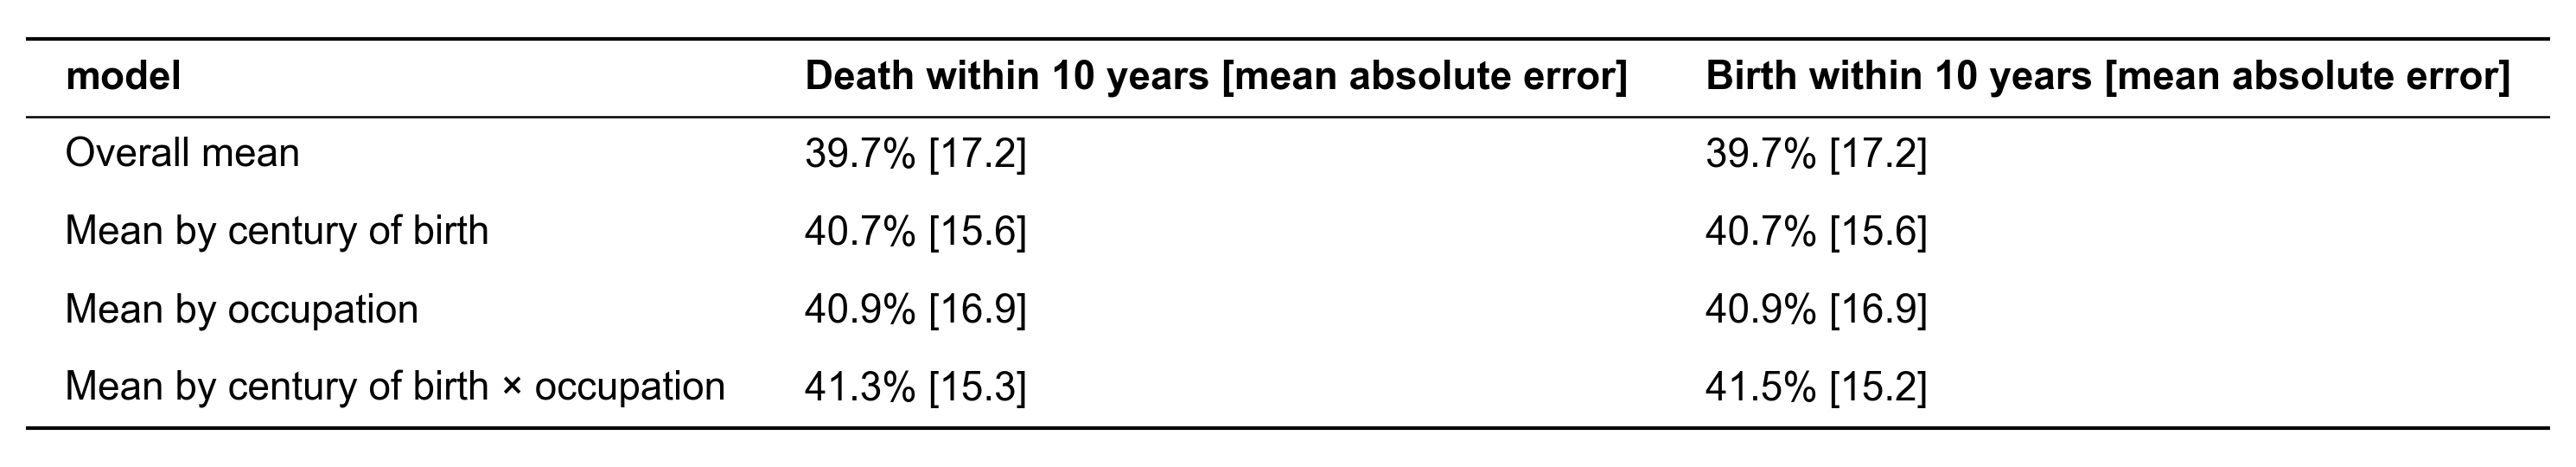

In [4]:
print(printed_outputs('01_age_at_death.ipynb', 6))
print(printed_outputs('01_age_at_death.ipynb', 14))
print(printed_outputs('01_age_at_death.ipynb', 16))
display(image_output('01_age_at_death.ipynb', 16))

### Imputed dates

In [5]:
rules = {'death': 'death_date', 'birth': 'birth_date'}
pl.DataFrame([con.sql(f'''
    SELECT '{missing}' AS missing,
           count(*) AS imputed,
           count(*) FILTER ({column}.field_provenance['year'].rule LIKE '%Wikidata gives only the%') AS replacing_a_coarse_date,
           count(*) FILTER ({column}.cohort.occupation IS NULL) AS from_the_century_alone,
           count(*) FILTER ({column}.field_provenance['year'].rule LIKE '%the nearest century%') AS from_the_nearest_century
    FROM '{AGE_AT_DEATH}'
    WHERE {column}.source = 'estimated'
''').pl().row(0, named=True) for missing, column in rules.items()])

missing,imputed,replacing_a_coarse_date,from_the_century_alone,from_the_nearest_century
str,i64,i64,i64,i64
"""death""","404,563","9,419","258,151",89
"""birth""","291,554","33,117","184,142",370


## Estimating the active life

### Work dates, positions held and their cleaning, from 03_b_active_life

In [6]:
for cell in [5, 7, 13, 15]:
    print(printed_outputs('03_b_active_life.ipynb', cell).split('shape')[0].strip())

36,804,752 work dates for 2,773,370 individuals
1,947,131 position statements for 979,289 individuals
1,947,131 statements for 979,289 individuals of the database
1,133,997 individuals with dated works or positions
1,133,994 after dropping those with no birth or death spanning over 100 years
555,912 of 1,133,994 active lives
404,674 with the start and the end in different years


In [7]:
for cell in [9, 11]:
    for output in json.load(open('03_b_active_life.ipynb'))['cells'][cell]['outputs']:
        print(''.join(output.get('data', {}).get('text/plain', '')))

shape: (5, 3)
┌─────────────────────────────────┬────────────┬─────────────┐
│ step                            ┆ work dates ┆ individuals │
│ ---                             ┆ ---        ┆ ---         │
│ str                             ┆ i64        ┆ i64         │
╞═════════════════════════════════╪════════════╪═════════════╡
│ start                           ┆ 36804752   ┆ 2773370     │
│ 1. publication dates only, no … ┆ 9637863    ┆ 599887      │
│ 2. outside the lifetime         ┆ 9479750    ┆ 584832      │
│ 3. publication over 100 years … ┆ 9478965    ┆ 584832      │
│ 4. inceptions spanning over 10… ┆ 9478728    ┆ 584786      │
└─────────────────────────────────┴────────────┴─────────────┘
shape: (3, 3)
┌────────────────────────┬───────────┬─────────────┐
│ step                   ┆ positions ┆ individuals │
│ ---                    ┆ ---       ┆ ---         │
│ str                    ┆ i64       ┆ i64         │
╞════════════════════════╪═══════════╪═════════════╡
│ start       

### Sources of the observed active lives (Table 4), century-averaged ages and model scores (Table 5)

train: 323,740, test: 80,934
best model, start of the active life: median by century of birth × occupation; end: median by century of birth × occupation


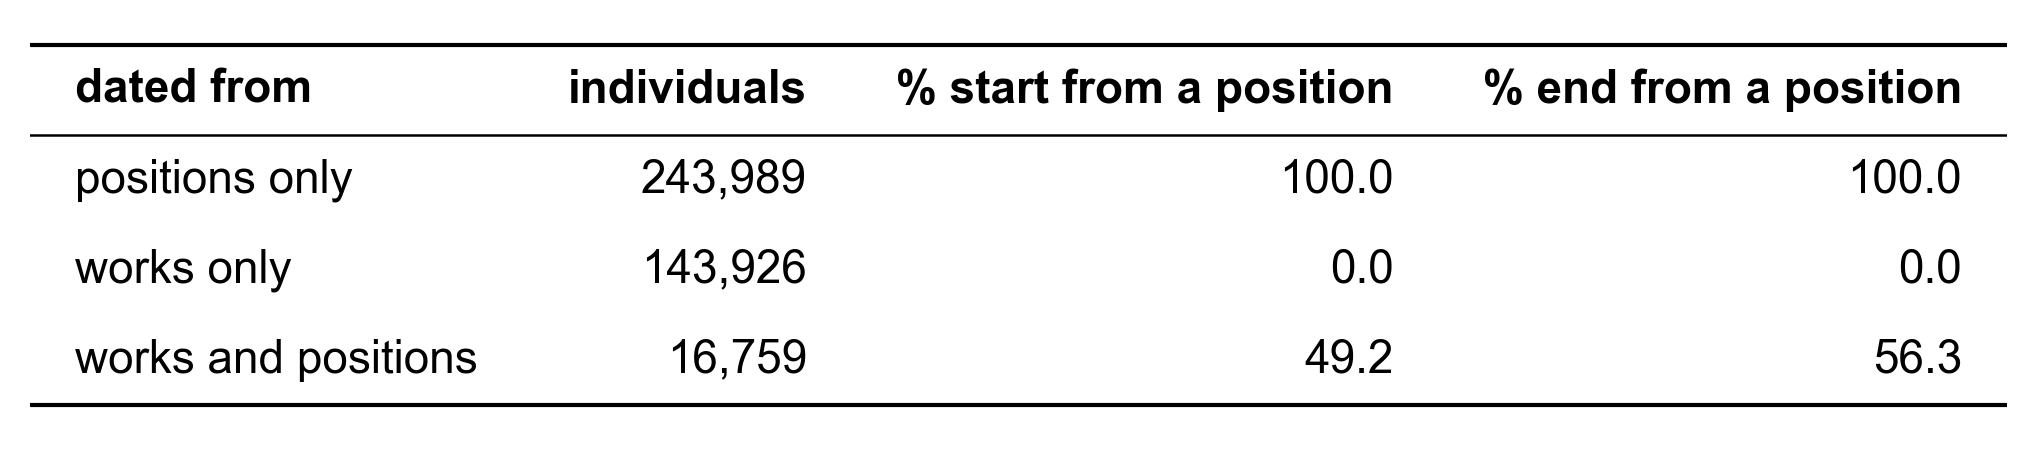

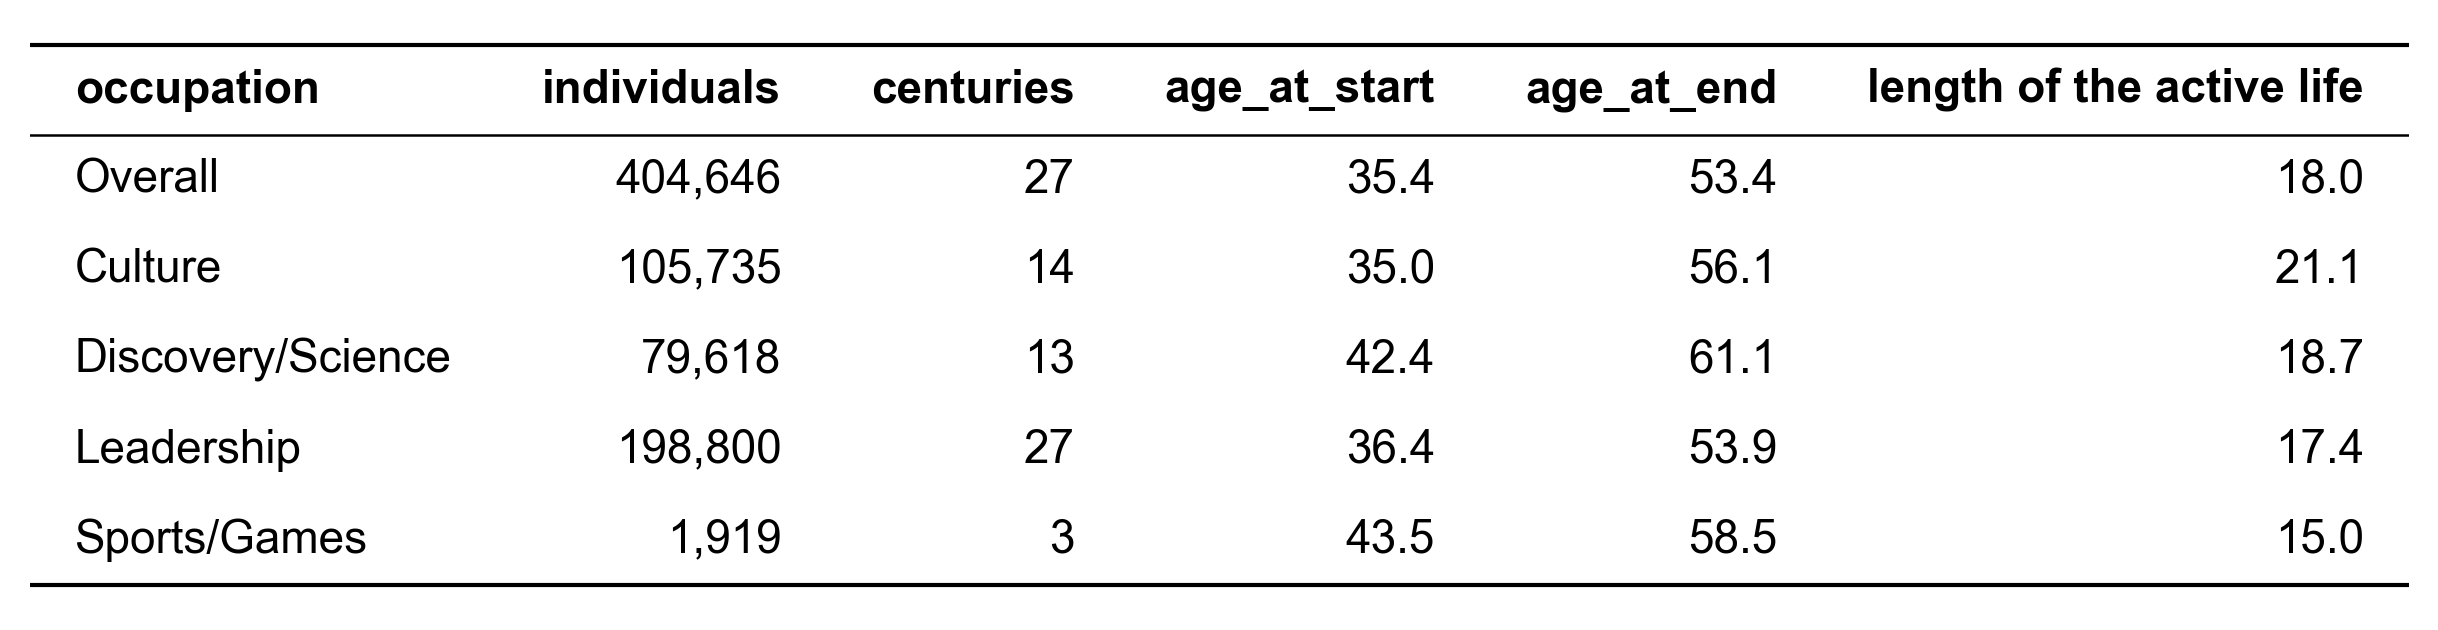

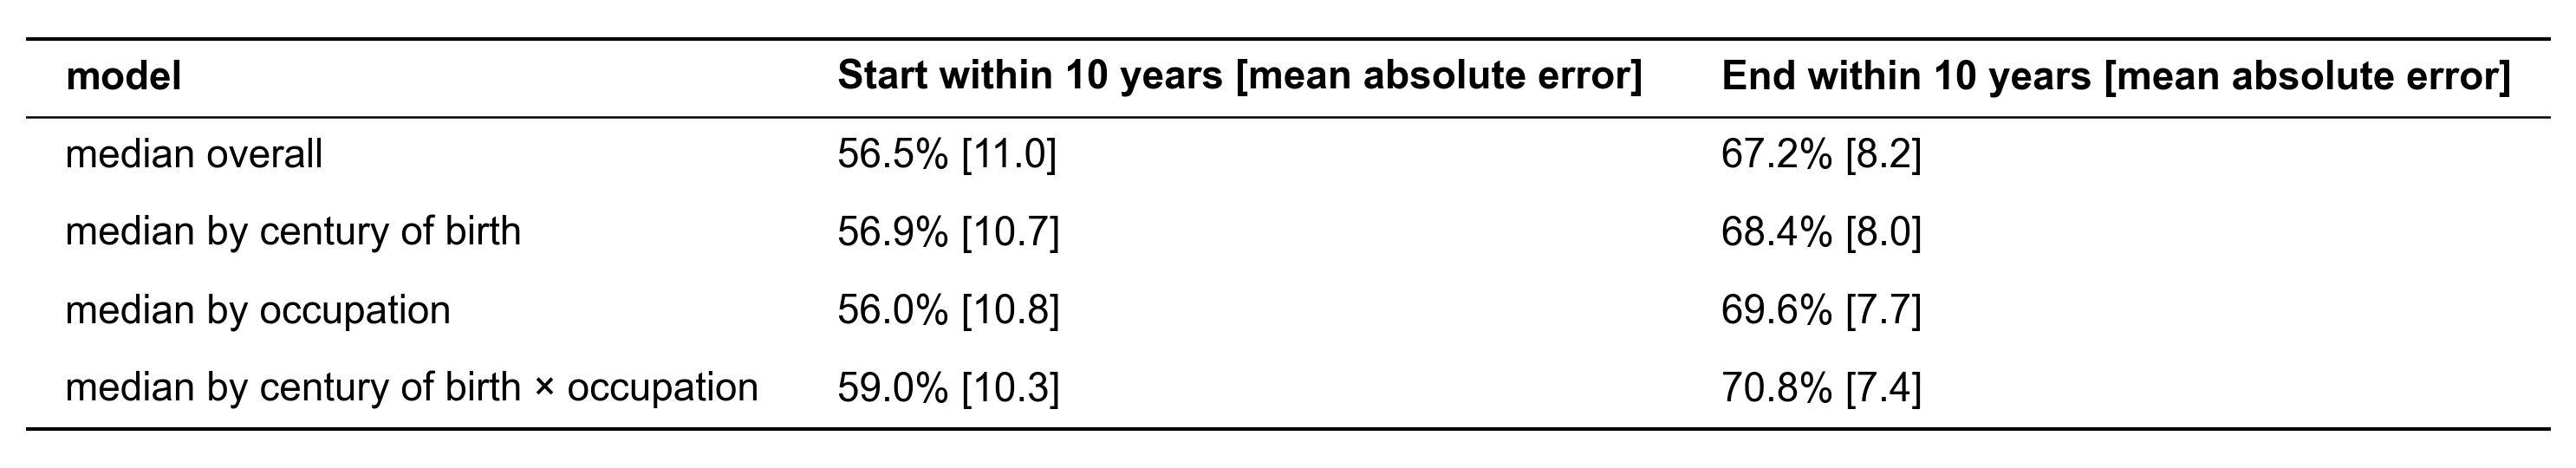

In [8]:
print(printed_outputs('03_b_active_life.ipynb', 26))
for cell in [17, 18, 28]:
    display(image_output('03_b_active_life.ipynb', cell))

### Predicted active lives (Table 6)

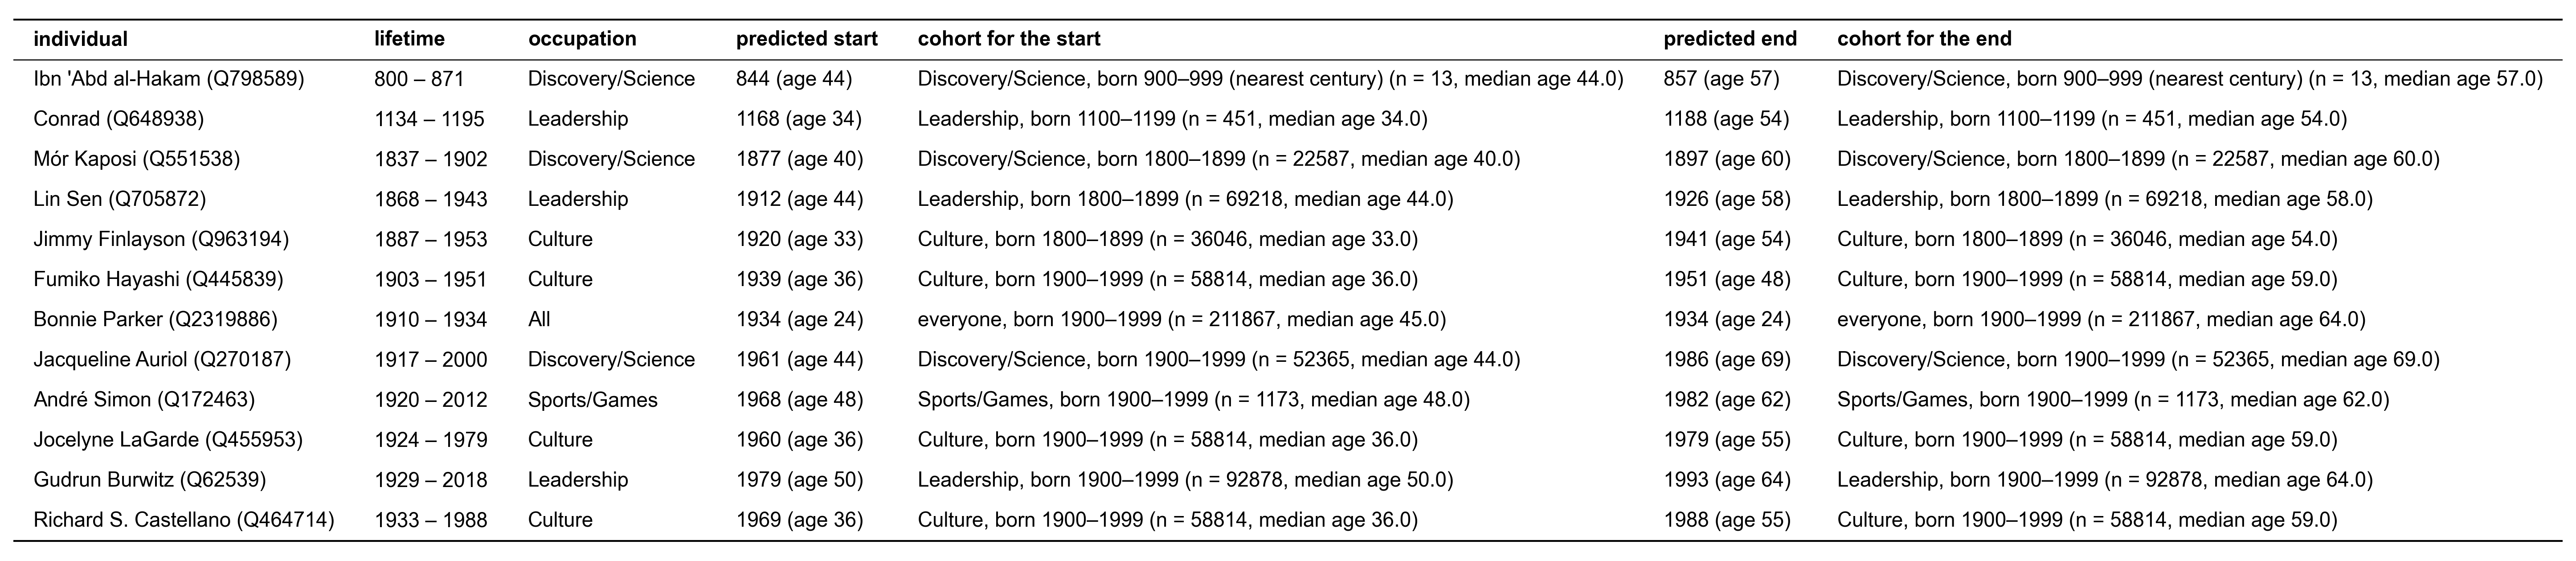

In [9]:
display(image_output('03_b_active_life.ipynb', 30))

### Observed, estimated and truncated active lives

In [10]:
con.sql(f'''
    SELECT count(*) FILTER (active_life.start_of_active_life.source = 'dated works and positions') AS observed,
           count(*) FILTER (active_life.start_of_active_life.source = 'dated works and positions'
                            AND active_life.start_of_active_life.year < active_life.end_of_active_life.year) AS observed_over_several_years,
           count(*) FILTER (active_life.start_of_active_life.source = 'dated works and positions'
                            AND active_life.start_of_active_life.year = active_life.end_of_active_life.year) AS observed_in_a_single_year,
           count(*) FILTER (active_life.start_of_active_life.source = 'estimated') AS estimated,
           count(*) FILTER (active_life.start_of_active_life.source = 'estimated'
                            AND active_life.start_of_active_life.field_provenance['year'].rule LIKE '%estimated%birth%') AS estimated_from_an_estimated_birth
    FROM '{ACTIVE_LIFE}' AS active_life
''').pl()

observed,observed_over_several_years,observed_in_a_single_year,estimated,estimated_from_an_estimated_birth
i64,i64,i64,i64,i64
"972,148","775,044","197,104","4,100,202","275,188"


In [11]:
truncated = con.sql(f'''
    SELECT count(*) AS imputed_with_a_death_year,
           count(*) FILTER (active_life.start_of_active_life.year = active_life.end_of_active_life.year) AS zero_years,
           count(*) FILTER (active_life.start_of_active_life.year < active_life.end_of_active_life.year
                            AND active_life.end_of_active_life.field_provenance['year'].rule LIKE '%capped at the death year%') AS shortened
    FROM '{ACTIVE_LIFE}' AS active_life
    JOIN '{AGE_AT_DEATH}' AS dates ON dates.qid = active_life.qid
    WHERE active_life.start_of_active_life.source = 'estimated' AND dates.death_date.year IS NOT NULL
''').pl()
truncated.with_columns((100 * pl.col('zero_years') / pl.col('imputed_with_a_death_year')).round(1).alias('zero (%)'),
                       (100 * pl.col('shortened') / pl.col('imputed_with_a_death_year')).round(1).alias('shortened (%)'))

imputed_with_a_death_year,zero_years,shortened,zero (%),shortened (%)
i64,i64,i64,f64,f64
"3,445,613","263,397","436,243",7.6,12.7


### Who died before the active life of their cohort begins

Imputed active lives of zero years, split into exclusive groups in this order: Holocaust victims (English Wikidata description), other deaths during the First or the Second World War, other deaths before the age of 15, everyone else. Military occupations and royal or noble families are counted within their group.

263,397 imputed active lives of zero years; 24,838 died before 15, 710 of them royal or noble


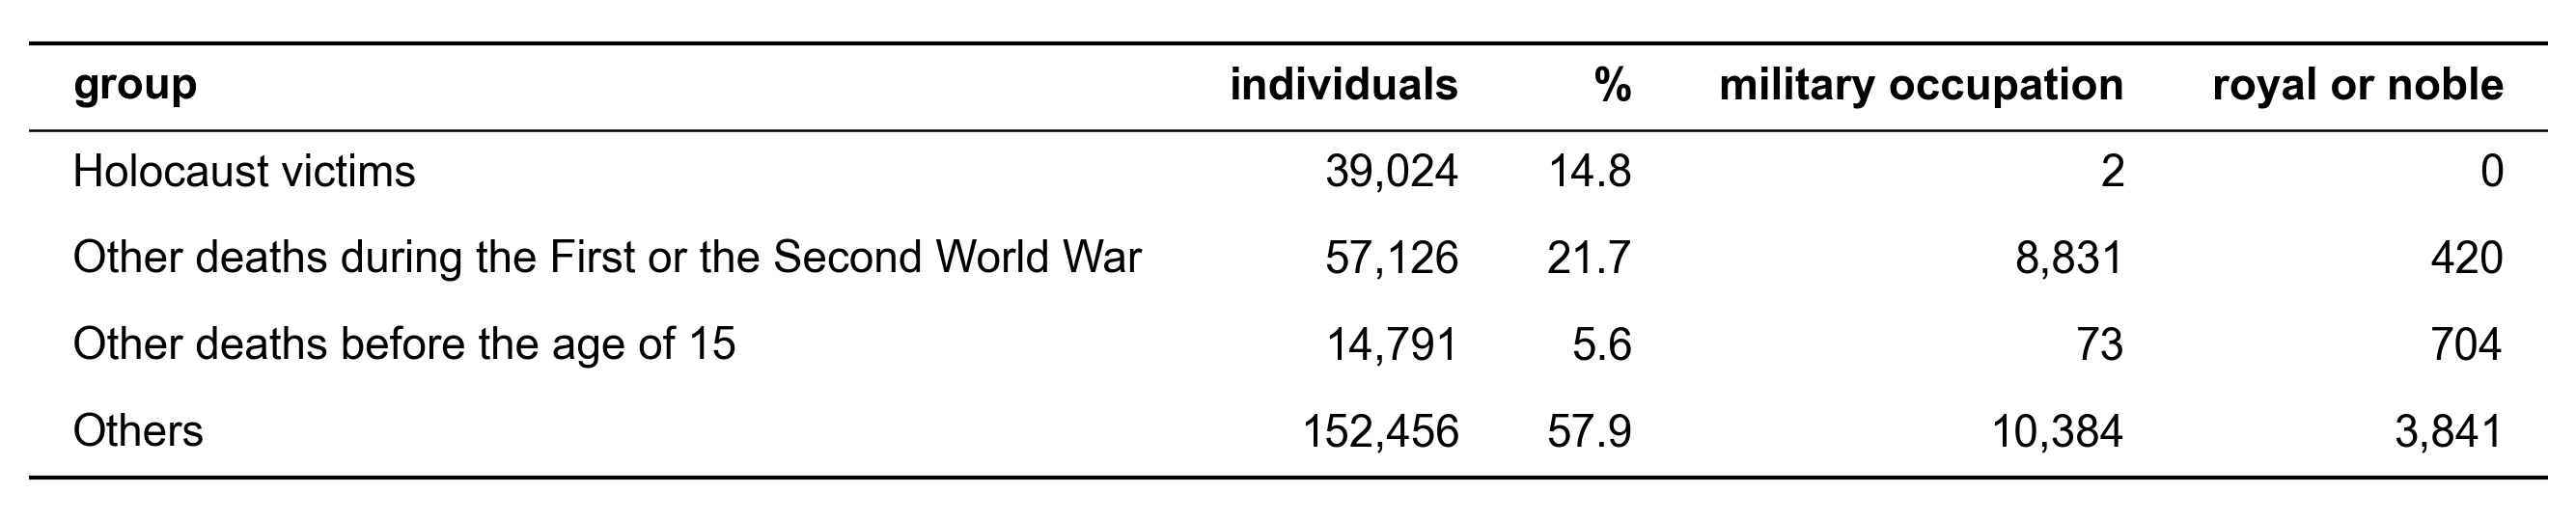

In [12]:
war = ' OR '.join(f'individual_enriched.death_date.year BETWEEN {first} AND {last}' for first, last in WAR_YEARS)
zero = con.sql(f'''
    SELECT individual.entity.qid AS qid,
           coalesce(lower(individual.entity.description), '') LIKE '%holocaust%' AS holocaust,
           {war} AS war,
           individual_enriched.death_date.year - individual_enriched.birth_date.year < {CHILD_AGE} AS child,
           list_has_any([o.entity.qid FOR o IN individual.occupation], $military) AS military,
           list_has_any([o.entity.qid FOR o IN individual.occupation], $royal) OR regexp_matches(coalesce(lower(individual.entity.description), ''), $royal_words) AS royal
    FROM '{ACTIVE_LIFE}' AS active_life
    JOIN individual ON individual.entity.qid = active_life.qid
    JOIN individual_enriched ON individual_enriched.entity.qid = active_life.qid
    WHERE active_life.start_of_active_life.source = 'estimated' AND active_life.start_of_active_life.year = active_life.end_of_active_life.year
''', params={'military': MILITARY, 'royal': ROYAL_OCCUPATIONS, 'royal_words': ROYAL_WORDS}).pl()
assert zero.height == truncated['zero_years'][0]
group = (pl.when('holocaust').then(pl.lit('Holocaust victims'))
         .when('war').then(pl.lit('Other deaths during the First or the Second World War'))
         .when('child').then(pl.lit(f'Other deaths before the age of {CHILD_AGE}'))
         .otherwise(pl.lit('Others')))
order = ['Holocaust victims', 'Other deaths during the First or the Second World War', f'Other deaths before the age of {CHILD_AGE}', 'Others']
died_before = (
    zero.with_columns(group.alias('group'))
    .group_by('group').agg(pl.len().alias('individuals'), pl.col('military').sum().alias('military occupation'), pl.col('royal').sum().alias('royal or noble'))
    .sort(pl.col('group').replace_strict(order, list(range(len(order)))))
    .with_columns((100 * pl.col('individuals') / zero.height).alias('%'))
    .select('group', 'individuals', '%', 'military occupation', 'royal or noble')
)
print(f'{zero.height:,} imputed active lives of zero years; {zero["child"].sum():,} died before {CHILD_AGE}, {(zero["child"] & zero["royal"]).sum():,} of them royal or noble')
show_table(died_before, decimals=1)

### Table 6: predicted active lives

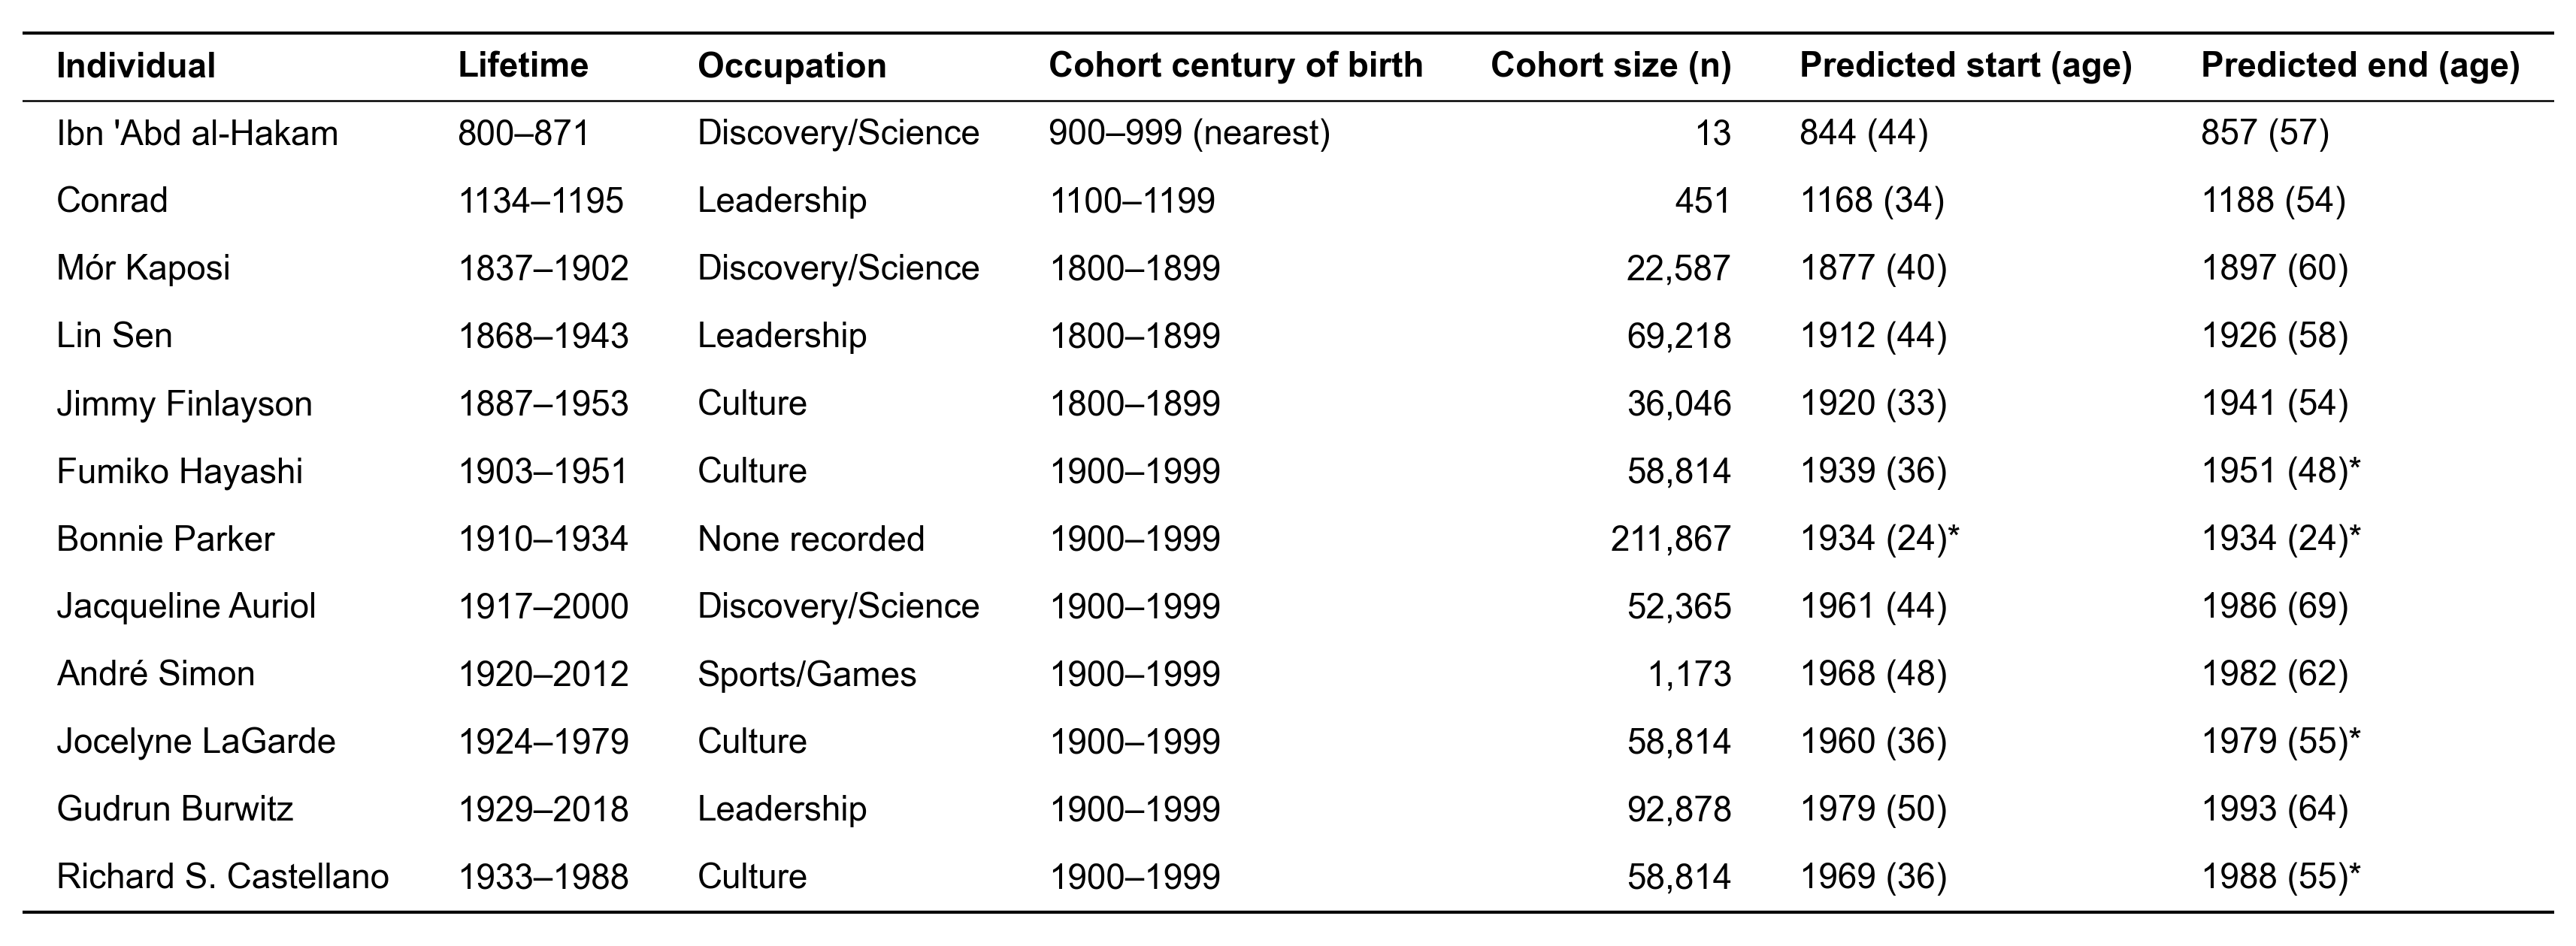

In [13]:
cohort_year = lambda end: pl.format('{} ({}){}', pl.col(f'{end}_year'), pl.col(f'{end}_year') - pl.col('birth_year'),
                                    pl.when(pl.col(f'{end}_rule').str.contains('capped')).then(pl.lit('*')).otherwise(pl.lit('')))
examples = con.sql(f'''
    SELECT coalesce(individual.entity.label_en, individual.entity.label_non_en) AS name,
           individual_enriched.birth_date.year AS birth_year, individual_enriched.death_date.year AS death_year,
           active_life.start_of_active_life.cohort.occupation AS occupation,
           active_life.start_of_active_life.cohort.century AS cohort_century,
           active_life.start_of_active_life.cohort.individuals AS cohort_size,
           active_life.start_of_active_life.year AS start_year, active_life.start_of_active_life.field_provenance['year'].rule AS start_rule,
           active_life.end_of_active_life.year AS end_year, active_life.end_of_active_life.field_provenance['year'].rule AS end_rule
    FROM '{ACTIVE_LIFE}' AS active_life
    JOIN individual ON individual.entity.qid = active_life.qid
    JOIN individual_enriched ON individual_enriched.entity.qid = active_life.qid
    WHERE list_contains($qids, active_life.qid)
''', params={'qids': TABLE_6}).pl().sort('birth_year')
assert examples.height == len(TABLE_6)
nearest = pl.when(pl.col('cohort_century') != pl.col('birth_year') // 100 * 100).then(pl.lit(' (nearest)')).otherwise(pl.lit(''))
show_table(examples.select(
    pl.col('name').alias('Individual'),
    pl.format('{}–{}', 'birth_year', 'death_year').alias('Lifetime'),
    pl.col('occupation').fill_null('None recorded').alias('Occupation'),
    pl.format('{}–{}{}', 'cohort_century', pl.col('cohort_century') + 99, nearest).alias('Cohort century of birth'),
    pl.col('cohort_size').map_elements(lambda n: f'{n:,}', return_dtype=pl.String).alias('Cohort size (n)'),
    cohort_year('start').alias('Predicted start (age)'),
    cohort_year('end').alias('Predicted end (age)'),
))

## Dates added by the imputation (Table 7)

In [14]:
dates = con.sql(f'''
    SELECT individual_enriched.entity.qid AS qid,
           individual_enriched.birth_date.year AS birth_year,
           individual_enriched.death_date.year AS death_year,
           individual_enriched.birth_date.source AS birth_source,
           individual_enriched.death_date.source AS death_source,
           individual_enriched.birth_date.coarse_label IS NOT NULL OR individual_enriched.death_date.coarse_label IS NOT NULL AS coarse,
           len(individual.floruit_date) > 0 AS floruit,
           active_life.start_of_active_life.source AS active_source,
           active_life.start_of_active_life.year < active_life.end_of_active_life.year AS several_years
    FROM individual_enriched
    JOIN individual ON individual.entity.qid = individual_enriched.entity.qid
    LEFT JOIN '{ACTIVE_LIFE}' AS active_life ON active_life.qid = individual_enriched.entity.qid
''').pl()
assert dates['qid'].is_unique().all()
wikidata_birth = (pl.col('birth_source') == 'wikidata') & pl.col('birth_year').is_not_null()
wikidata_death = (pl.col('death_source') == 'wikidata') & pl.col('death_year').is_not_null()
observed = (pl.col('active_source') == 'dated works and positions') & pl.col('several_years')
dates.select(
    pl.len().alias('individuals'),
    wikidata_birth.sum().alias('wikidata birth'),
    (pl.col('birth_source') == 'estimated').sum().alias('estimated birth'),
    wikidata_death.sum().alias('wikidata death'),
    (pl.col('death_source') == 'estimated').sum().alias('estimated death'),
    observed.sum().alias('observed active life'),
    (pl.col('active_source') == 'estimated').sum().alias('estimated active life'),
)

individuals,wikidata birth,estimated birth,wikidata death,estimated death,observed active life,estimated active life
u32,u32,u32,u32,u32,u32,u32
"13,002,897","7,349,797","291,554","3,501,133","404,563","775,044","4,100,202"


In [15]:
no_life_dates = dates.filter(pl.col('birth_year').is_null() & pl.col('death_year').is_null())
no_date = no_life_dates.filter(~pl.col('coarse') & ~pl.col('floruit') & pl.col('active_source').is_null())
print(f'{no_life_dates.height:,} individuals with neither a birth nor a death year after imputation, {no_date.height:,} of them with no date at all')

5,361,544 individuals with neither a birth nor a death year after imputation, 5,098,788 of them with no date at all


## Individuals with century-level dates only (Table 8, Figure 4)

In [16]:
con.sql(f'''
    SELECT count(*) AS individuals,
           count(*) FILTER (birth_date IS NOT NULL AND death_date IS NOT NULL) AS coarse_birth_and_death,
           count(*) FILTER (birth_date IS NOT NULL AND death_date IS NULL) AS coarse_birth_only,
           count(*) FILTER (birth_date IS NULL AND death_date IS NOT NULL) AS coarse_death_only
    FROM '{COARSE}'
''').pl()

individuals,coarse_birth_and_death,coarse_birth_only,coarse_death_only
i64,i64,i64,i64
"108,030","17,829","87,151","3,050"


In [17]:
print(printed_outputs('05_coarse_dates.ipynb', 7).split('shape')[0])
for output in json.load(open('05_coarse_dates.ipynb'))['cells'][7]['outputs']:
    print(''.join(output.get('data', {}).get('text/plain', '')))

7,749,373 → 7,744,611 after leaving out the 4,762 placed by a millennium only

shape: (60, 4)
┌─────────┬─────────────┬─────────────┬───────────────┐
│ century ┆ individuals ┆ only coarse ┆ % only coarse │
│ ---     ┆ ---         ┆ ---         ┆ ---           │
│ str     ┆ u32         ┆ u32         ┆ f64           │
╞═════════╪═════════════╪═════════════╪═══════════════╡
│ 73rd BC ┆ 1           ┆ 1           ┆ 100.0         │
│ 44th BC ┆ 1           ┆ 1           ┆ 100.0         │
│ 43rd BC ┆ 2           ┆ 0           ┆ 0.0           │
│ 37th BC ┆ 1           ┆ 1           ┆ 100.0         │
│ 35th BC ┆ 1           ┆ 1           ┆ 100.0         │
│ 33rd BC ┆ 1           ┆ 0           ┆ 0.0           │
│ 32nd BC ┆ 8           ┆ 2           ┆ 25.0          │
│ 31st BC ┆ 5           ┆ 3           ┆ 60.0          │
│ 30th BC ┆ 20          ┆ 6           ┆ 30.0          │
│ 29th BC ┆ 14          ┆ 9           ┆ 64.3          │
│ 28th BC ┆ 25          ┆ 24          ┆ 96.0          │
│ 27th BC 